# Bandung Road Network Analysis: Explanation & Interpretation

In [2]:
import os, pickle, random, warnings
from collections import defaultdict

os.environ['PYTHONIOENCODING'] = 'utf-8'
os.environ['PYTHONUTF8'] = '1'
warnings.filterwarnings('ignore')

import city2graph as c2g
import geopandas as gpd
import networkx as nx
import numpy as np
import seaborn as sns
import powerlaw
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from scipy import stats
from shapely.geometry import box as shapely_box
from sklearn.metrics import classification_report
from sklearn.preprocessing import MinMaxScaler
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch_geometric.utils import from_networkx

sns.set_style('darkgrid')   
plt.rcParams.update({
    'figure.figsize': (14, 5),
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
})

---
## 1. Network Construction & Visualization

We use **city2graph** to download Bandung's road network from Overture Maps, build a
NetworkX graph, and produce multi-scale visualisations (full city → city centre → neighbourhood).

### 1.1 Download from Overture Maps via city2graph

In [2]:
print('Downloading Overture Maps data for Bandung ...')

c2g.load_overture_data(
    place_name='Bandung, Indonesia',
    types=['segment', 'connector'],
    output_dir='./datasets/',
    prefix="bandung_",
    save_to_file=True,
    return_data=False,
)

{}

### 1.2 Projecting to Local UTM & Graph Construction

The road network data is reprojected from WGS-84 coordinates into a local UTM coordinate reference system (CRS) to ensure distance calculations use meters instead of degrees. The road segments are then processed and converted into a NetworkX graph using City2Graph.

In [6]:
segments_gdf = gpd.read_file('./datasets/bandung_segment.geojson')
connectors_gdf = gpd.read_file('./datasets/bandung_connector.geojson')

DRIVEABLE = {'motorway', 'trunk', 'primary', 'secondary', 'tertiary',
             'residential', 'service', 'living_street', 'unclassified'}

segments_gdf = segments_gdf[
    (segments_gdf['subtype'] == 'road') &
    (segments_gdf['class'].isin(DRIVEABLE))
].reset_index(drop=True)

print(f'  Raw segments   : {len(segments_gdf):,}')
print(f'  Raw connectors : {len(connectors_gdf):,}')

  Raw segments   : 58,640
  Raw connectors : 60,301


In [7]:
# Project to local UTM
local_crs = segments_gdf.estimate_utm_crs()
segments_gdf = segments_gdf.to_crs(local_crs)
connectors_gdf = connectors_gdf.to_crs(local_crs)

print(f'CRS: {local_crs}')

CRS: EPSG:32748


In [43]:
print('\nProcessing segments (split at connectors, cluster endpoints) ...')
processed_segments = c2g.process_overture_segments(
    segments_gdf,
    connectors_gdf=connectors_gdf,
    get_barriers=True,
    threshold=1.0,
)
print(f'  Processed segments : {len(processed_segments):,}')


Processing segments (split at connectors, cluster endpoints) ...
  Processed segments : 71,589


If multiple connected components exist, only the largest connected component (LCC) is retained to ensure path-based metrics such as average path length and betweenness centrality remain valid.

In [44]:
G_raw = c2g.segments_to_graph(processed_segments, as_nx=True)
print(f'Nodes : {G_raw.number_of_nodes():,}')
print(f'Edges : {G_raw.number_of_edges():,}')

n_cc = nx.number_connected_components(G_raw)
print(f'  Connected components: {n_cc}')

if n_cc > 1:
    largest_cc = max(nx.connected_components(G_raw), key=len)
    G = nx.convert_node_labels_to_integers(
        G_raw.subgraph(largest_cc).copy(),
        ordering='sorted',
    )
    print(f'  Trimmed → Nodes: {G.number_of_nodes():,} | Edges: {G.number_of_edges():,}')
else:
    G = G_raw
    print('  Graph is fully connected. No trimming needed.')

print(f'  Node label range: {min(G.nodes())} – {max(G.nodes())}')

lengths = [d['length'] for _, _, d in G.edges(data=True)]
print(f'\nEdge length — mean: {np.mean(lengths):.1f} m ' 
      f'| median: {np.median(lengths):.1f} m ' 
      f'| max: {np.max(lengths):.1f} m')

Removed 84 invalid geometries


Nodes : 58,183
Edges : 70,738
  Connected components: 318
  Trimmed → Nodes: 56,463 | Edges: 69,162
  Node label range: 0 – 56462

Edge length — mean: 52.7 m | median: 39.1 m | max: 4693.6 m


In [45]:
with open('./datasets/bandung_drive.pkl', 'wb') as f:
    pickle.dump(G, f)
print('Graph saved → ./datasets/bandung_drive.pkl')

Graph saved → ./datasets/bandung_drive.pkl


### 1.3 Static Overview — Full City

he complete Bandung road network is visualized using different colors and line widths based on road hierarchy. Major roads such as motorways and primary roads appear more prominent, while residential and service roads form the dense local street structure.

In [3]:
with open('./datasets/bandung_drive.pkl', 'rb') as f:
    G = pickle.load(f)
print(f'Loaded → Nodes: {G.number_of_nodes():,} | Edges: {G.number_of_edges():,}')

Loaded → Nodes: 56,463 | Edges: 69,162


In [4]:
BGCOLOR = '#ffffff'
DEFAULT_EDGE_COLOR = '#444444'

HIGHWAY_COLORS = {
    'motorway': '#e31a1c', 'trunk': '#fd8d3c', 'primary': '#fecc5c',
    'secondary': '#ffffb2', 'tertiary': '#a1d99b', 'residential': '#636363',
    'living_street': '#9ecae1', 'service':  '#969696', 'unclassified': '#bdbdbd'
}

HIGHWAY_WIDTHS = {
    'motorway': 2.0,
    'trunk': 1.8,
    'primary': 1.4,
    'secondary': 1.0,
    'tertiary': 0.7,
    'residential': 0.4,
    'living_street': 0.35,
    'service': 0.3,
    'unclassified': 0.3,
}

In [5]:
def edge_style(G, color_map, width_map, default_color, default_width):
    colors, widths = [], []
    for _, _, d in G.edges(data=True):
        hw = d.get('class', '')
        hw = hw[0] if isinstance(hw, list) else hw
        colors.append(color_map.get(hw, default_color))
        widths.append(width_map.get(hw, default_width))

    return colors, widths

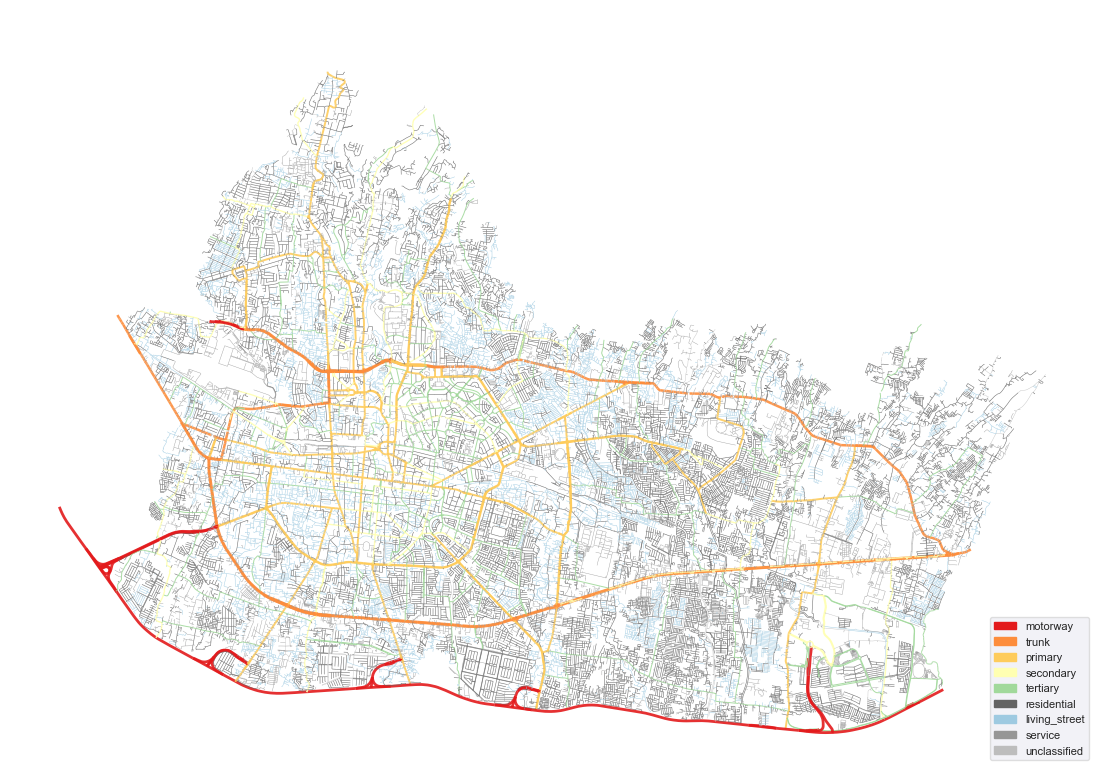

In [6]:
ec, ew = edge_style(G, HIGHWAY_COLORS, HIGHWAY_WIDTHS, DEFAULT_EDGE_COLOR, 0.4)

ax = c2g.plot_graph(
    graph=G,
    bgcolor=BGCOLOR,
    figsize=(14, 14),
    markersize=0,
    edge_color=ec,
    edge_linewidth=ew,
    edge_alpha=0.9,
)
ax.set_title('Bandung Road Network — Full City', color='white', fontsize=14, pad=10)
legend_patches = [mpatches.Patch(color=c, label=hw) for hw, c in HIGHWAY_COLORS.items()]
ax.legend(handles=legend_patches, loc='lower right', fontsize=8, framealpha=0.6)
plt.savefig('bandung_overview.png', dpi=150, bbox_inches='tight', facecolor=BGCOLOR)
plt.show()

### 1.4 Multi-Scale Subgraph Navigation (Zoom In / Zoom Out)

We define three bounding boxes — full city, city centre, and the Dago/ITB neighbourhood —
and use `c2g.clip_graph` to extract each subgraph for focused inspection.

In [7]:
def make_bbox_polygon(center_lat, center_lon, dist_m, crs):
    """
    Build a square bounding-box polygon of half-side `dist_m` metres
    around (center_lat, center_lon), projected into `crs`.
    """
    d_lat = dist_m / 111_000
    d_lon = dist_m / (111_000 * np.cos(np.radians(center_lat)))
    bbox  = shapely_box(
        center_lon - d_lon, center_lat - d_lat,
        center_lon + d_lon, center_lat + d_lat,
    )
    gdf = gpd.GeoDataFrame(geometry=[bbox], crs='EPSG:4326')
    return gdf.to_crs(crs).geometry.iloc[0]

In [8]:
SCALES = {
    'Full City\n(Bandung — ~12 km radius)': {
        'lat': -6.9175, 'lon': 107.6191, 'dist_m': 12_000,
    },
    'City Centre\n(Braga / Asia Afrika — 2 km)': {
        'lat': -6.9175, 'lon': 107.6088, 'dist_m': 2_000,
    },
    'Neighborhood\n(Dago / ITB — 600 m)': {
        'lat': -6.8971, 'lon': 107.6099, 'dist_m': 600,
    },
}

sample_node = next(iter(G.nodes()))
pos_x, pos_y = G.nodes[sample_node]['pos']

_tmp = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy([pos_x], [pos_y]),
    crs='EPSG:32748'
)
local_crs = _tmp.crs

subgraphs = {}
for label, cfg in SCALES.items():
    poly = make_bbox_polygon(cfg['lat'], cfg['lon'], cfg['dist_m'], local_crs)
    G_clip = c2g.clip_graph(G, poly)
    subgraphs[label] = G_clip
    print(f'{label.splitlines()[0]} → '
          f'Nodes: {G_clip.number_of_nodes():,} | '
          f'Edges: {G_clip.number_of_edges():,}')

Full City → Nodes: 56,372 | Edges: 69,061
City Centre → Nodes: 5,896 | Edges: 7,353
Neighborhood → Nodes: 563 | Edges: 659


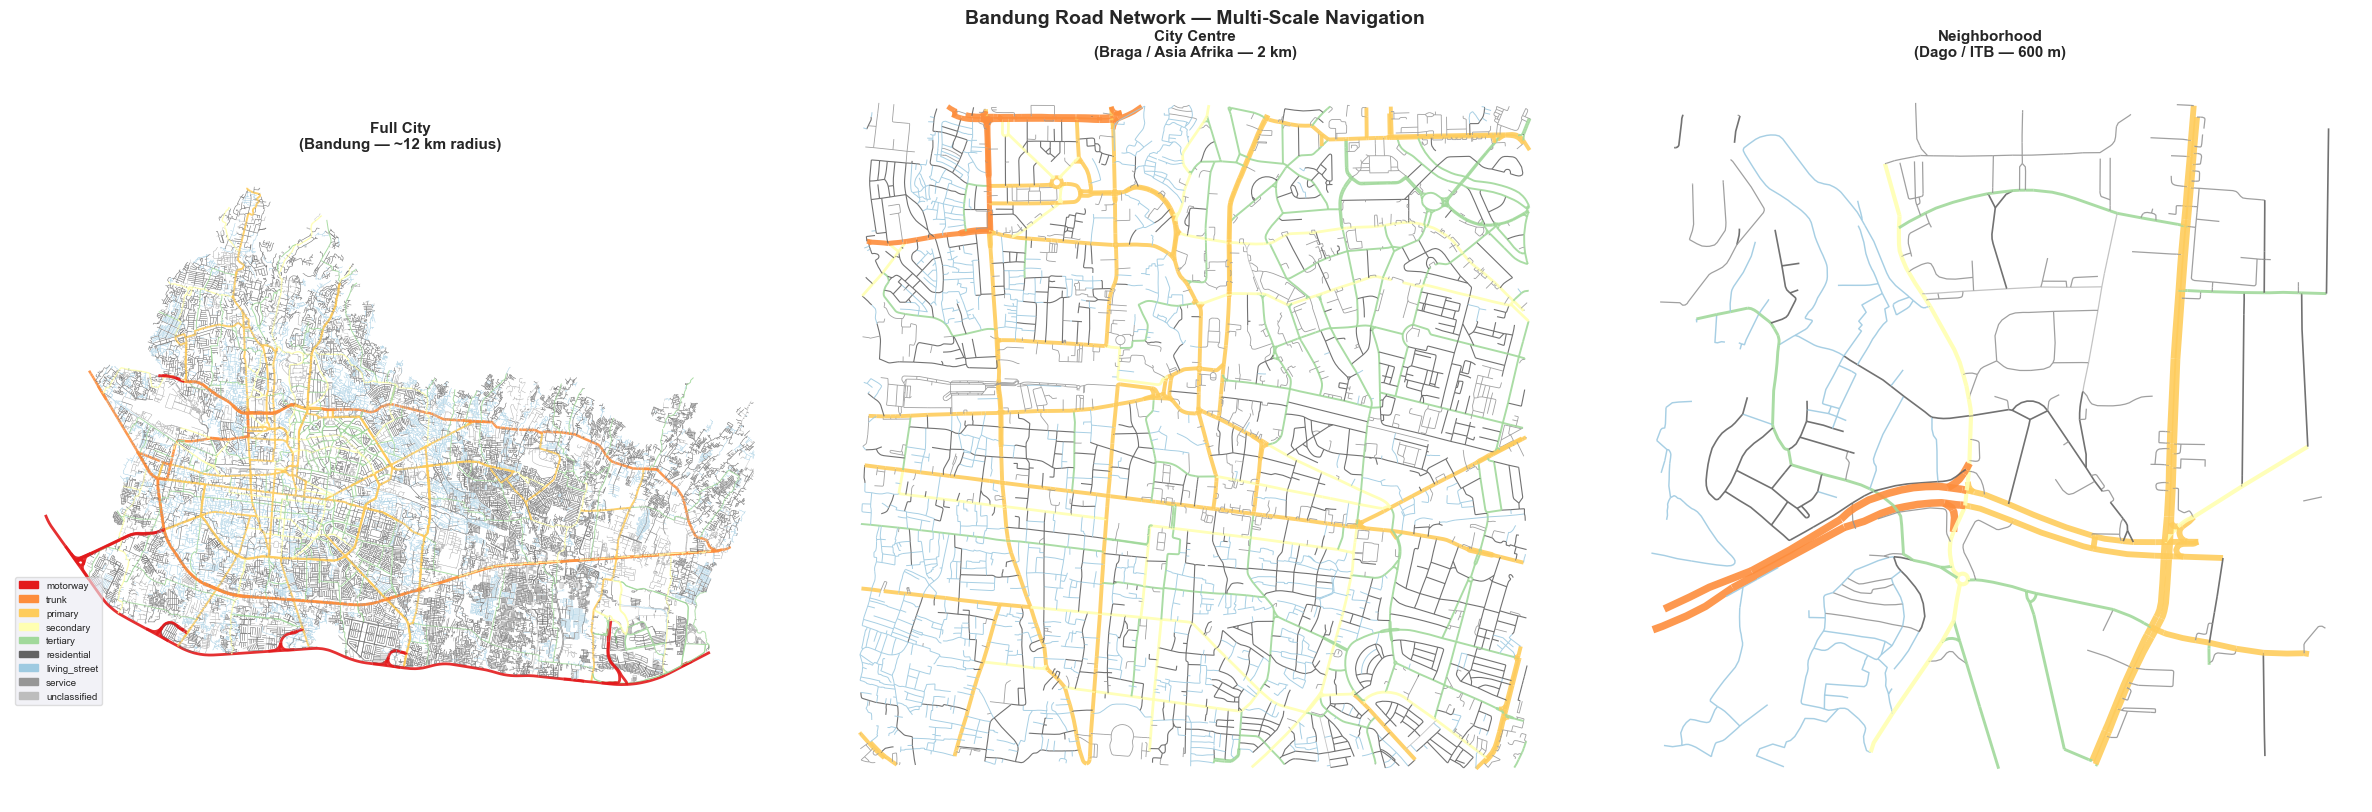

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(24, 8), facecolor=BGCOLOR)

for ax, (label, G_sub) in zip(axes, subgraphs.items()):
    ec, ew = edge_style(G_sub, HIGHWAY_COLORS, HIGHWAY_WIDTHS, DEFAULT_EDGE_COLOR, 0.4)

    if 'City Centre' in label:
        ew = [w * 2.0 for w in ew]
    
    elif 'Neighborhood' in label:
        ew = [w * 3.0 for w in ew]

    c2g.plot_graph(
        G_sub,
        ax=ax,
        bgcolor=BGCOLOR,
        markersize=0,
        edge_color=ec,
        edge_linewidth=ew,
        edge_alpha=0.9,
    )
    ax.set_title(label, fontsize=11, fontweight='bold', pad=10)

legend_patches = [mpatches.Patch(color=c, label=hw) for hw, c in HIGHWAY_COLORS.items()]
axes[0].legend(handles=legend_patches, loc='lower left', fontsize=7, framealpha=0.6)

plt.suptitle(
    'Bandung Road Network — Multi-Scale Navigation',
    fontsize=14, fontweight='bold', y=1.01,
)
plt.tight_layout()
plt.savefig('bandung_multiscale.png', dpi=150, bbox_inches='tight', facecolor=BGCOLOR)
plt.show()

## 2. Structural Network Analysis

### 2.1 Basic Stats

Basic network metrics such as nodes, edges, average degree, clustering coefficient, and average path length are computed to describe Bandung’s road structure

In [9]:
G_simple = nx.Graph(G) 

N_rn = G_simple.number_of_nodes()
E_rn = G_simple.number_of_edges()
k_avg = 2 * E_rn / N_rn

degrees_rn = dict(G_simple.degree())

print(f'Nodes           : {N_rn:,}')
print(f'Edges           : {E_rn:,}')
print(f'Mean Degree (k) : {k_avg:.3f}')
print(f'Max Degree      : {max(degrees_rn.values())}')
print(f'Graph density   : {nx.density(G_simple):.6f}')

Nodes           : 56,463
Edges           : 69,162
Mean Degree (k) : 2.450
Max Degree      : 6
Graph density   : 0.000043


In [ ]:
cc_rn = nx.average_clustering(G_simple)
print(f'\nAvg Clustering coefficient   : {cc_rn:.4f}')

random.seed(42)
sample_nodes = random.sample(list(G_simple.nodes()), min(500, N_rn))
apl_samples  = []
for src in sample_nodes:
    lens = nx.single_source_shortest_path_length(G_simple, src)
    apl_samples.extend(v for v in lens.values() if v > 0)
apl_rn = float(np.mean(apl_samples))
print(f'Approx. APL (500-source)      : {apl_rn:.2f}')

fit_rn = powerlaw.Fit(list(degrees_rn.values()), discrete=True, verbose=False)

_, p = fit_rn.distribution_compare('power_law', 'lognormal')
print(f'Power law alpha               : {fit_rn.power_law.alpha:.4f}')
print()


Avg Clustering coefficient   : 0.0296
Approx. APL (500-source)      : 110.22
Power law alpha               : 1.7992


### 2.2 Reference Model Comparisons

Bandung’s road network is compared with three synthetic graph models: Erdős–Rényi (ER), Watts–Strogatz (WS), and Barabási–Albert (BA). The comparisons show that real road networks differ significantly from random, small-world, and scale-free networks because road connectivity is limited by geography and urban design. Unlike social or internet networks, road intersections have naturally bounded degrees and fewer shortcut connections.

In [9]:
p_er = k_avg / (N_rn - 1)
m_ba = max(1, int(round(k_avg / 2)))
k_ws = max(4, round(k_avg / 2) * 2)

beta_ws = 0.1

print(f'Reference N={N_rn:,}  |  ER p={p_er:.5f}  |  WS k={k_ws}  |  BA m={m_ba}')

Reference N=56,463  |  ER p=0.00004  |  WS k=4  |  BA m=1


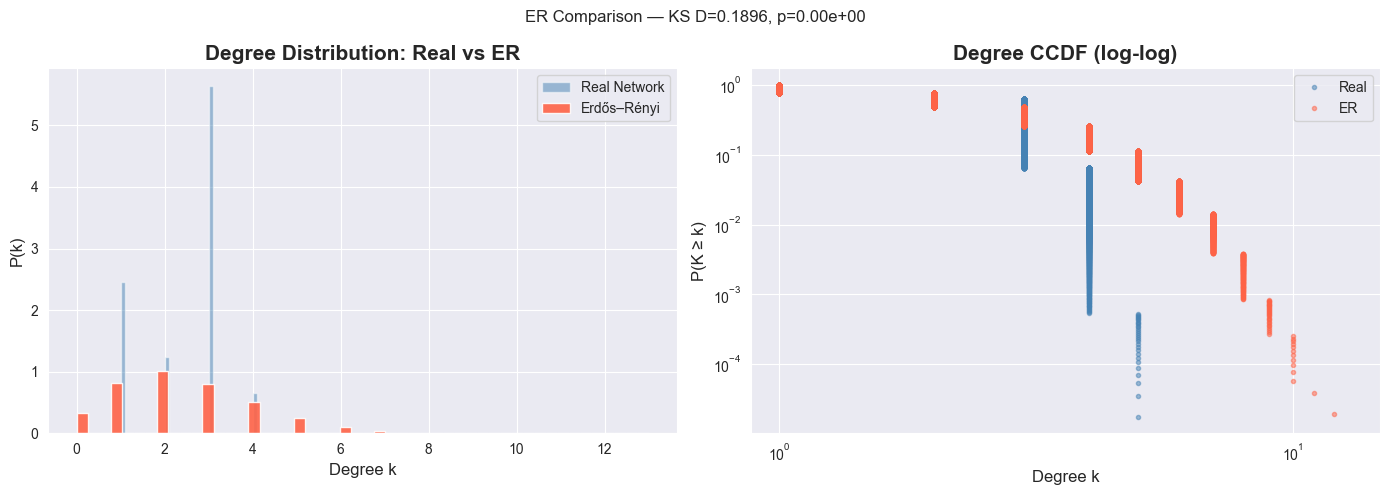

Real  — avg degree: 2.4498, std: 0.9340
ER    — avg degree: 2.4480, std: 1.5639
KS test: D=0.1896, p=0.00e+00
→ Significantly different



In [10]:
G_er = nx.fast_gnp_random_graph(N_rn, p_er, seed=42)

real_deg = np.array([d for _, d in G_simple.degree()])
er_deg = np.array([d for _, d in G_er.degree()])

ks_stat, ks_p = stats.ks_2samp(real_deg, er_deg)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(real_deg, bins=50, density=True, alpha=0.5, color='steelblue', label='Real Network')
axes[0].hist(er_deg, bins=50, density=True, alpha=0.9, color='tomato', label='Erdős–Rényi')
axes[0].set_xlabel('Degree k')
axes[0].set_ylabel('P(k)')
axes[0].set_title('Degree Distribution: Real vs ER')
axes[0].legend()

for arr, label, color in [(real_deg, 'Real', 'steelblue'), (er_deg, 'ER', 'tomato')]:
    sorted_d = np.sort(arr[arr > 0])
    ccdf = 1 - np.arange(1, len(sorted_d) + 1) / len(sorted_d)
    axes[1].loglog(sorted_d, ccdf, '.', alpha=0.5, label=label, color=color)
axes[1].set_xlabel('Degree k')
axes[1].set_ylabel('P(K ≥ k)')
axes[1].set_title('Degree CCDF (log-log)')
axes[1].legend()

plt.suptitle(f'ER Comparison — KS D={ks_stat:.4f}, p={ks_p:.2e}', fontsize=12)
plt.tight_layout()
plt.show()


print(f'Real  — avg degree: {real_deg.mean():.4f}, std: {real_deg.std():.4f}')
print(f'ER    — avg degree: {er_deg.mean():.4f}, std: {er_deg.std():.4f}')
print(f'KS test: D={ks_stat:.4f}, p={ks_p:.2e}')
print(f'→ {"Significantly different" if ks_p < 0.05 else "No significant difference"}')
print()

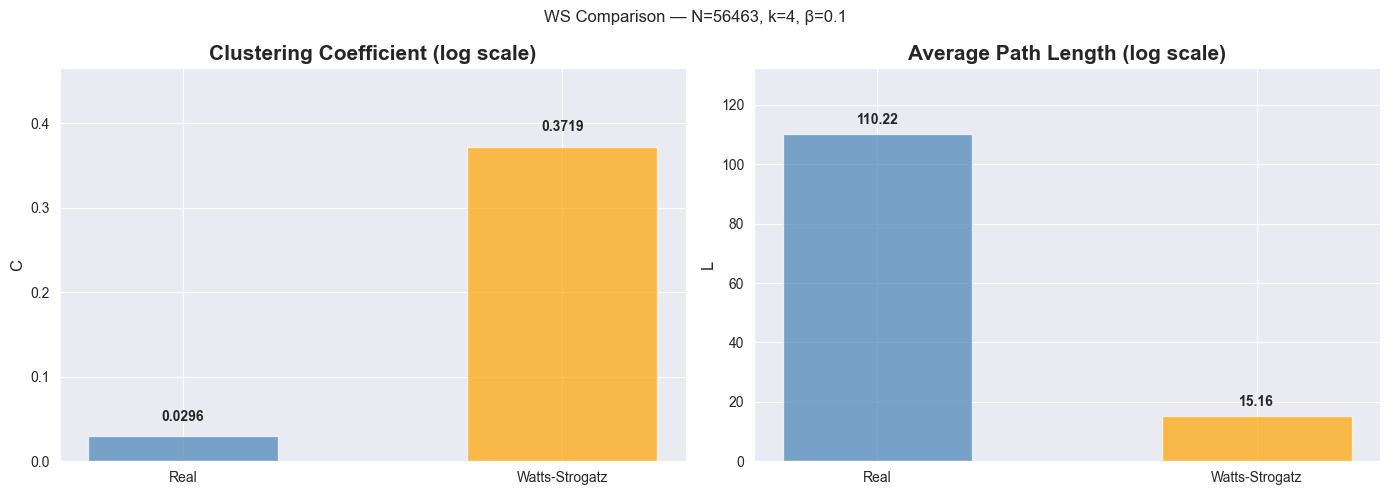

Metric                          Real         WS   Ratio (R/WS)
------------------------------------------------------------
Clustering coeff              0.0296     0.3719         0.0796
Avg path length             110.2202    15.1597         7.2706



In [11]:
G_ws = nx.watts_strogatz_graph(n=N_rn, k=k_ws, p=beta_ws, seed=42)

ws_cc = nx.average_clustering(G_ws)
ws_deg = np.array([d for _, d in G_ws.degree()])

random.seed(42)
sample = random.sample(list(G_ws.nodes()), min(500, len(G_ws)))
ws_apl_samples = []
for src in sample:
    lens = nx.single_source_shortest_path_length(G_ws, src)
    ws_apl_samples.extend(v for v in lens.values() if v > 0)
ws_apl = float(np.mean(ws_apl_samples))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

categories = ['Real', 'Watts-Strogatz']
cc_vals = [cc_rn, ws_cc]
apl_vals = [apl_rn, ws_apl]

axes[0].bar(categories, cc_vals, color=['steelblue', 'orange'], alpha=0.7, width=0.5)
axes[0].set_title('Clustering Coefficient (log scale)')
axes[0].set_ylabel('C')
for i, v in enumerate(cc_vals):
    axes[0].text(i, v + max(cc_vals) * 0.05, f'{v:.4f}', ha='center', fontweight='bold', fontsize=10)
axes[0].set_ylim(0, max(cc_vals) * 1.25)

axes[1].bar(categories, apl_vals, color=['steelblue', 'orange'], alpha=0.7, width=0.5)
axes[1].set_title('Average Path Length (log scale)')
axes[1].set_ylabel('L')
for i, v in enumerate(apl_vals):
    axes[1].text(i, v + max(apl_vals) * 0.03, f'{v:.2f}', ha='center', fontweight='bold', fontsize=10)
axes[1].set_ylim(0, max(apl_vals) * 1.2)

plt.suptitle(f'WS Comparison — N={N_rn}, k={k_ws}, β={beta_ws}', fontsize=12)
plt.tight_layout()
plt.show()
 
print(f'{"Metric":<25} {"Real":>10} {"WS":>10} {"Ratio (R/WS)":>14}')
print('-' * 60)
print(f'{"Clustering coeff":<25} {cc_rn:>10.4f} {ws_cc:>10.4f} {cc_rn/ws_cc:>14.4f}')
print(f'{"Avg path length":<25} {apl_rn:>10.4f} {ws_apl:>10.4f} {apl_rn/ws_apl:>14.4f}')
print()

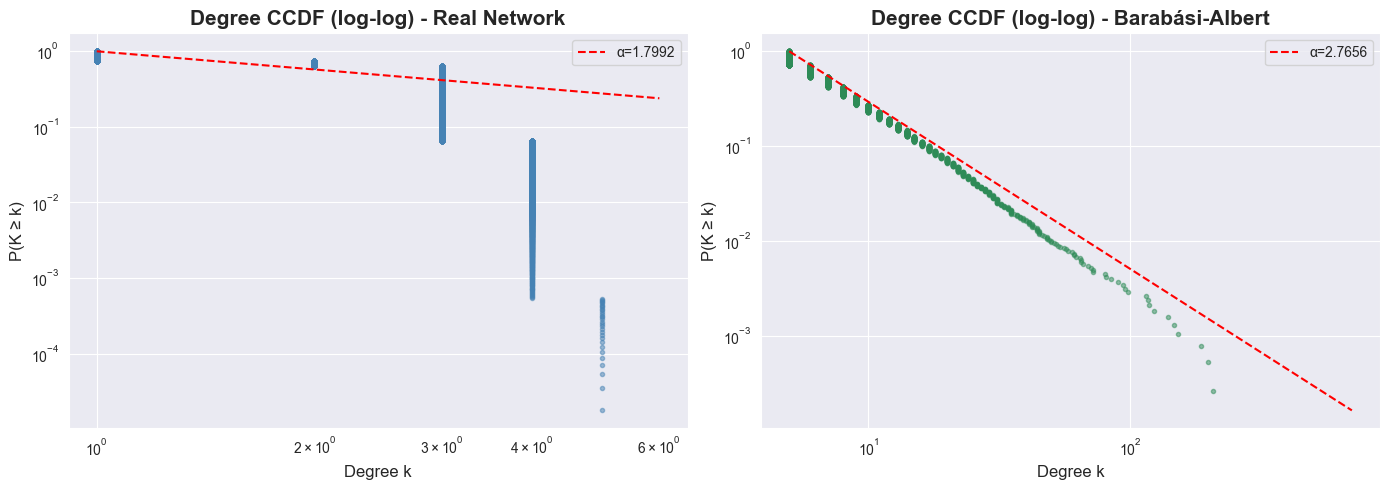

Metric                          Real         BA
----------------------------------------------
Power-law alpha               1.7992     2.7656
xmin                             1.0        5.0



In [12]:
G_ba = nx.barabasi_albert_graph(n=N_rn, m=m_ba, seed=42)

ba_deg = np.array([d for _, d in G_ba.degree()])
ba_fit = powerlaw.Fit(ba_deg, discrete=True, verbose=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, arr, model_fit, title, color in [
    (axes[0], real_deg, fit_rn, 'Real Network', 'steelblue'),
    (axes[1], ba_deg, ba_fit, 'Barabási-Albert', 'seagreen'),
]:
    sorted_d = np.sort(arr[arr >= model_fit.power_law.xmin])
    ccdf = 1 - np.arange(1, len(sorted_d) + 1) / len(sorted_d)
    ax.loglog(sorted_d, ccdf, '.', alpha=0.5, color=color)

    x = np.linspace(sorted_d.min(), sorted_d.max(), 200)
    alpha = model_fit.power_law.alpha
    xmin = model_fit.power_law.xmin
    C = xmin ** (alpha - 1)
    
    ax.loglog(x, C * x ** (-(alpha - 1)), 'r--', label=f'α={alpha:.4f}')
    ax.set_xlabel('Degree k')
    ax.set_ylabel('P(K ≥ k)')
    ax.set_title(f'Degree CCDF (log-log) - {title}')
    ax.legend()

plt.tight_layout()
plt.show()

print(f'{"Metric":<25} {"Real":>10} {"BA":>10}')
print('-' * 46)
print(f'{"Power-law alpha":<25} {fit_rn.power_law.alpha:>10.4f} {ba_fit.power_law.alpha:>10.4f}')
print(f'{"xmin":<25} {fit_rn.power_law.xmin:>10.1f} {ba_fit.power_law.xmin:>10.1f}')
print()

### 2.3 Centrality Analysis

Several centrality measures are used to identify important intersections in the network. Degree centrality highlights highly connected intersections, closeness centrality identifies locations with efficient access to the city, betweenness centrality reveals major traffic bottlenecks, and PageRank emphasizes intersections connected to important arterial roads.

In [13]:
# Betweenness 
betweenness_rn = nx.betweenness_centrality(G_simple, k=500, normalized=True, seed=42)

# PageRank
pr_rn = nx.pagerank(G, alpha=0.85, weight='length')

# Closeness
random.seed(42)
close_sources = random.sample(list(G_simple.nodes()), 500)
close_rn = {}
for src in close_sources:
    lengths = nx.single_source_shortest_path_length(G_simple, src)
    reachable = len(lengths) - 1
    total_dist = sum(v for v in lengths.values() if v > 0)
    if reachable > 0 and total_dist > 0:
        close_rn[src] = reachable / total_dist

# Degree
deg_cen_rn = {n: d / (N_rn - 1) for n, d in degrees_rn.items()}

print('Done')

Done


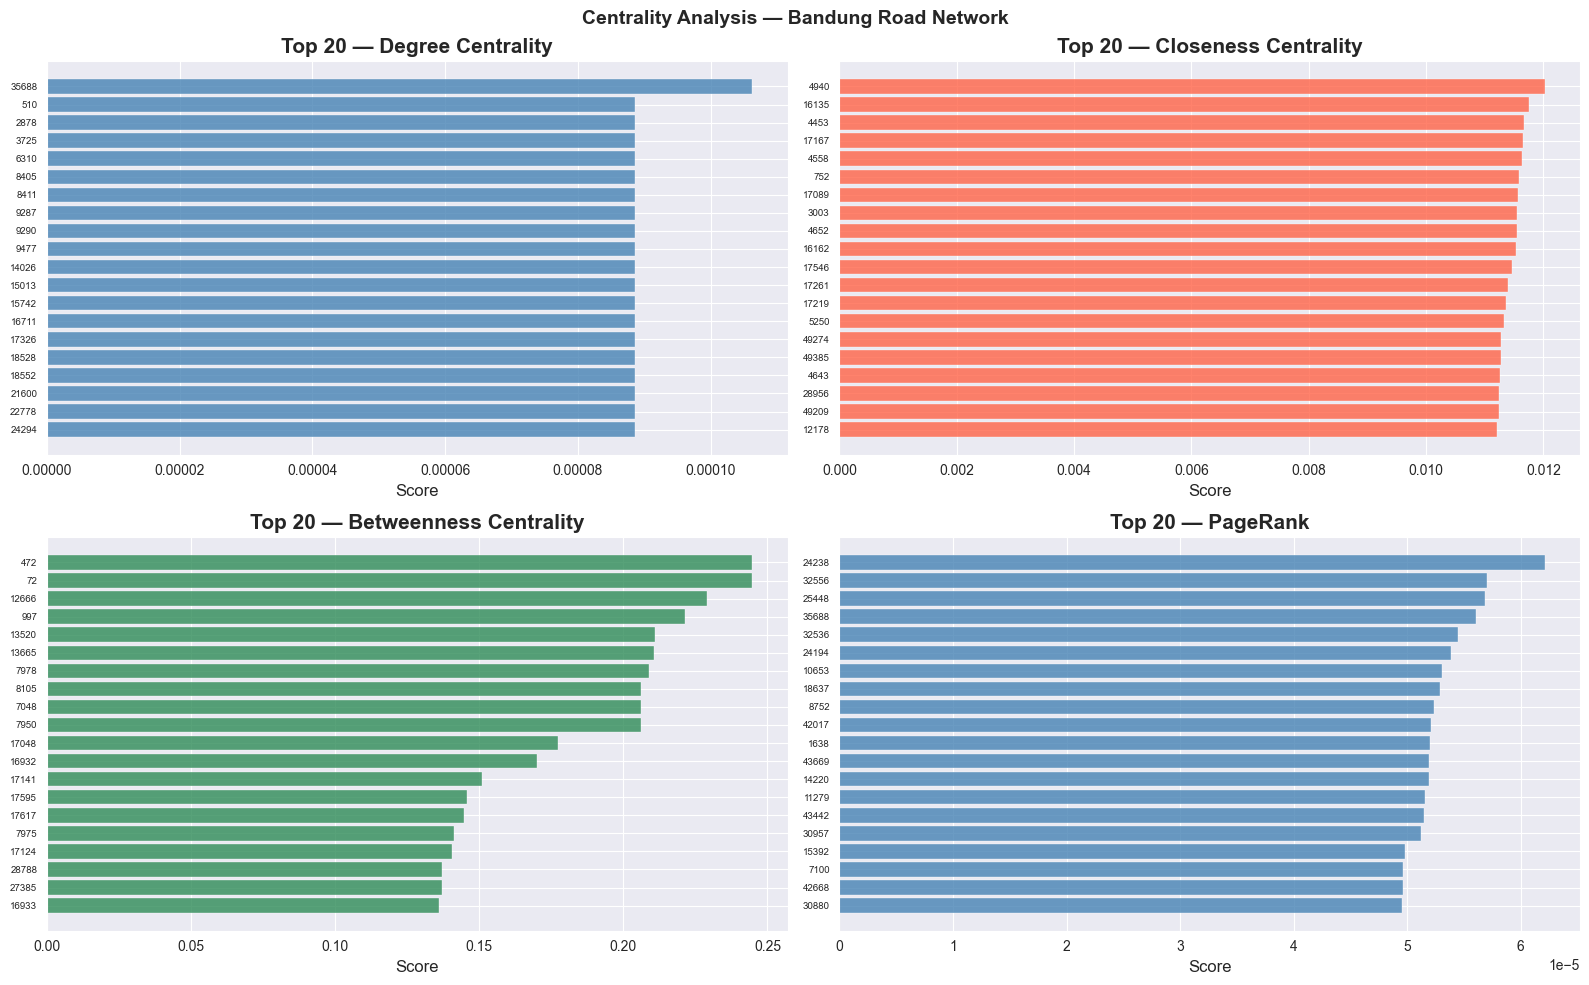

In [14]:
top_n = 20

measures = [
    (deg_cen_rn, 'Degree Centrality', 'steelblue'),
    (close_rn, 'Closeness Centrality', 'tomato'),
    (betweenness_rn, 'Betweenness Centrality', 'seagreen'),
    (pr_rn, 'PageRank', 'steelblue'),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, (measure, title, color) in zip(axes.flat, measures):
    top = sorted(measure.items(), key=lambda x: x[1], reverse=True)[:top_n]
    labels = [str(n)[-7:] for n, _ in top]
    vals = [v for _, v in top]
    ax.barh(labels[::-1], vals[::-1], color=color, alpha=0.8, edgecolor='white', linewidth=0.3)
    ax.set_xlabel('Score')
    ax.set_title(f'Top {top_n} — {title}', fontweight='bold')
    ax.tick_params(axis='y', labelsize=7)

plt.suptitle('Centrality Analysis — Bandung Road Network', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

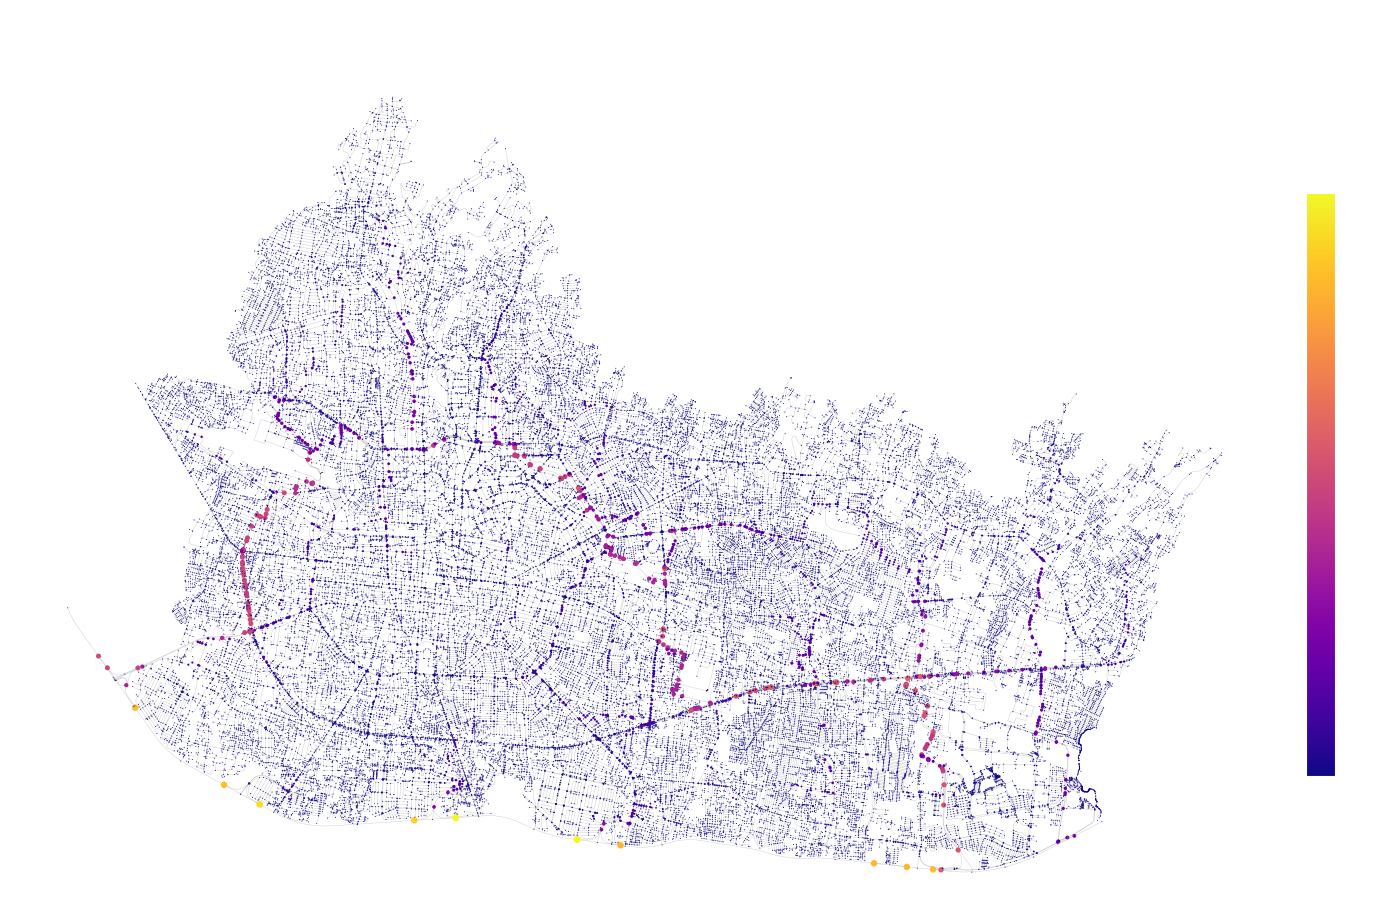

In [15]:
bw_arr = np.array([betweenness_rn.get(n, 0) for n in G.nodes()])
bw_norm = (bw_arr - bw_arr.min()) / (bw_arr.max() - bw_arr.min() + 1e-12)
cmap_bw = plt.cm.plasma
node_sz = [0.5 + v * 25 for v in bw_norm]

ax = c2g.plot_graph(
    G,
    markersize=0,
    edge_color='#2a2a2a',
    edge_linewidth=0.25,
    bgcolor=BGCOLOR,
    figsize=(14, 14),
)
fig = ax.get_figure()

xs = np.array([G.nodes[n]['pos'][0] for n in G.nodes()])
ys = np.array([G.nodes[n]['pos'][1] for n in G.nodes()])

sc = ax.scatter(
    xs, ys,
    c=bw_norm, cmap='plasma',
    s=node_sz, zorder=3, linewidths=0,
    norm=plt.Normalize(0, 1),
)

ax.set_title('Betweenness Centrality — Bandung Road Network\n'
             '(brighter / larger = higher betweenness)',
             color='white', fontsize=13, pad=10,
)

cbar = fig.colorbar(sc, ax=ax, fraction=0.022, pad=0.02)
cbar.set_label('Betweenness Centrality', color='white', fontsize=10)
cbar.ax.yaxis.set_tick_params(color='white', labelsize=8)
plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')

plt.tight_layout()
plt.show()

### 2.4 Vulnerability Analysis — Articulation Points & Bridges

The analysis identifies articulation points and bridge edges, which represent critical parts of the network whose removal would disconnect sections of the city.

In [16]:
art_points = set(nx.articulation_points(G_simple))
bridges = list(nx.bridges(G_simple))
bridge_set = set(map(frozenset, bridges))

n_art = len(art_points)
n_bridge = len(bridges)
pct_art = n_art / N_rn * 100
pct_bri = n_bridge / E_rn * 100

print('=' * 55)
print('Vulnerability Analysis — Articulation Points & Bridges')
print('=' * 55)
print(f'  Nodes total            : {N_rn:,}')
print(f'  Articulation points    : {n_art:,}  ({pct_art:.2f}% of nodes)')
print()
print(f'  Edges total            : {E_rn:,}')
print(f'  Bridge edges           : {n_bridge:,}  ({pct_bri:.2f}% of edges)')
print('=' * 55)

Vulnerability Analysis — Articulation Points & Bridges
  Nodes total            : 56,463
  Articulation points    : 15,887  (28.14% of nodes)

  Edges total            : 69,162
  Bridge edges           : 18,592  (26.88% of edges)


In [17]:
art_bw = sorted(
    [(n, betweenness_rn.get(n, 0)) for n in art_points],
    key=lambda x: x[1], reverse=True
)[:20]
print('\nTop-20 articulation points by betweenness centrality:')
print(f'  {"Node":>10}  {"Betweenness":>14}  {"Degree":>8}')
for n, bw in art_bw:
    print(f'  {n:>10}  {bw:>14.6f}  {G_simple.degree(n):>8}')


Top-20 articulation points by betweenness centrality:
        Node     Betweenness    Degree
        8686        0.133951         3
       12016        0.130871         3
       17583        0.128228         4
       27364        0.123038         3
       23287        0.122185         3
       14122        0.121478         3
       14123        0.121474         3
       15966        0.121467         3
       16159        0.121450         3
       23308        0.121147         3
       24195        0.120555         3
       16138        0.120468         3
       16436        0.119791         3
       16434        0.119753         3
       16435        0.119741         3
       23548        0.117397         3
       24193        0.116727         3
       16087        0.116540         3
       16404        0.116144         3
       16199        0.113759         3


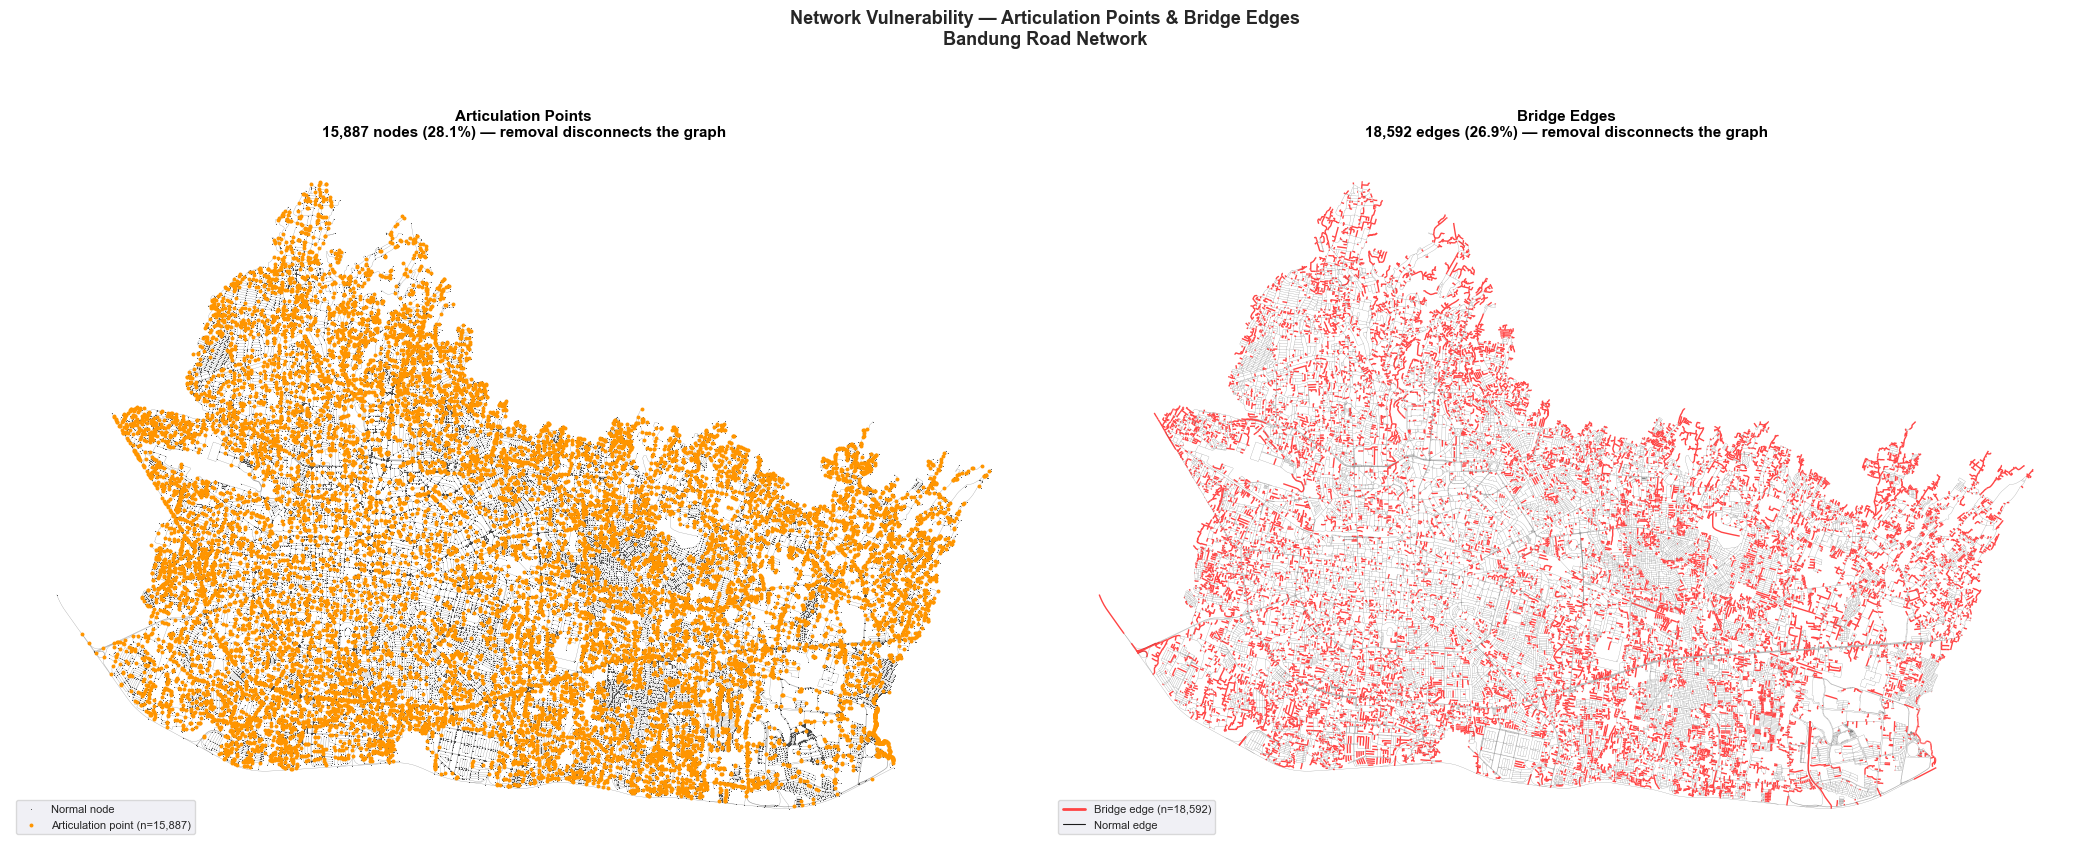

Figure saved → bandung_vulnerability.png


In [18]:
node_list = list(G.nodes())
xs = np.array([G.nodes[n]['pos'][0] for n in node_list])
ys = np.array([G.nodes[n]['pos'][1] for n in node_list])

is_art = np.array([n in art_points for n in node_list])

bridge_ec  = []
bridge_ew  = []
bridge_za  = []
for u, v, _ in G.edges(data=True):
    if frozenset({u, v}) in bridge_set:
        bridge_ec.append('#ff4444')
        bridge_ew.append(1.0)
        bridge_za.append(1.0)
    else:
        bridge_ec.append('#1c1c1c')
        bridge_ew.append(0.18)
        bridge_za.append(0.5)

fig, axes = plt.subplots(1, 2, figsize=(21, 9), facecolor=BGCOLOR)

ax_a = axes[0]
c2g.plot_graph(
    G, ax=ax_a, bgcolor=BGCOLOR,
    markersize=0, edge_color='#1c1c1c', edge_linewidth=0.2, edge_alpha=0.5,
)

ax_a.scatter(
    xs[~is_art], ys[~is_art],
    c='#444444', s=0.4, zorder=2, linewidth=0, label='Normal node',
)

ax_a.scatter(
    xs[is_art], ys[is_art],
    c='#ff9500', s=8, zorder=4, linewidths=0, label=f'Articulation point (n={n_art:,})',
)
ax_a.set_title(
    f'Articulation Points\n'
    f'{n_art:,} nodes ({pct_art:.1f}%) — removal disconnects the graph',
    color='black', fontsize=11, fontweight='bold', pad=10,
)
ax_a.legend(loc='lower left', fontsize=8, framealpha=0.7)

ax_b = axes[1]
c2g.plot_graph(
    G, ax=ax_b, bgcolor=BGCOLOR,
    markersize=0, edge_color=bridge_ec,
    edge_linewidth=bridge_ew,
    edge_alpha=bridge_za,
)

ax_b.plot([], [], '-', color='#ff4444', lw=2,   label=f'Bridge edge (n={n_bridge:,})')
ax_b.plot([], [], '-', color='#1c1c1c', lw=0.8, label='Normal edge')
ax_b.set_title(
    f'Bridge Edges\n'
    f'{n_bridge:,} edges ({pct_bri:.1f}%) — removal disconnects the graph',
    color='black', fontsize=11, fontweight='bold', pad=10,
)
ax_b.legend(loc='lower left', fontsize=8, framealpha=0.7)

plt.suptitle(
    'Network Vulnerability — Articulation Points & Bridge Edges\n'
    'Bandung Road Network',
    fontsize=13, fontweight='bold', y=1.01,
)
plt.tight_layout()
plt.savefig('bandung_vulnerability.png', dpi=150, bbox_inches='tight', facecolor=BGCOLOR)
plt.show()
print('Figure saved → bandung_vulnerability.png')

## 3. Network Dynamics

The FCR model simulates how traffic congestion spreads through Bandung’s road network. Each intersection can be in a free-flow, congested, or recovered state. Congestion spreads to nearby intersections, gradually clears over time, and may occasionally reappear. This approach models realistic urban traffic behavior, where jams propagate through connected roads and recover slowly.

In [19]:
STATE_COLORS = {'F': '#3a7fc1', 'C': '#e84040', 'R': '#3db87a'}

def fcr_simulation(G, seed_nodes, beta, gamma, delta,
                   max_steps=200, snapshot_steps=None, rng_seed=None):
    """
    Free-flow -> Congested -> Recovered simulation.

    Args:
        G: the contact network
        seed_nodes: initial infected nodes
        beta: congestion spread probability
        gamma: recovery probability
        delta: re-susceptibility  probability
        max_steps: maximum number of timesteps
        rng_seed: random seed for reproducibility
    
    Returns:
        history: dict
        states: dict
    """
    rng = np.random.default_rng(rng_seed)
    state = {node: 'F' for node in G.nodes()}
    for node in seed_nodes:
        state[node] = 'C'
    
    history = defaultdict(list)
    snap_set = set(snapshot_steps or [])
    snapshots = {}

    for step in range(max_steps):
        if step in snap_set:
            snapshots[step] = state.copy()

        f_c = sum(1 for v in state.values() if v == 'F')
        c_c = sum(1 for v in state.values() if v == 'C')
        r_c = sum(1 for v in state.values() if v == 'R')

        history['F'].append(f_c)
        history['C'].append(c_c)
        history['R'].append(r_c)

        # Early stopping - no congested nodes remain
        if c_c == 0:
            break

        new_state = state.copy()
        for node in G.nodes():
            if state[node] == 'C':
                # recovery
                if rng.random() < gamma:
                    new_state[node] = 'R'
            
            elif state[node] == 'R':
                if rng.random() < delta:
                    new_state[node] = 'F'
            
            elif state[node] == 'F':
                # Congestion from each congested neighbour independently
                congested_neighbors = [nb for nb in G.neighbors(node)
                                      if state[nb] == 'C']
                for _ in congested_neighbors:
                    if rng.random() < beta:
                        new_state[node] = 'C'
                        break
        
        state = new_state
    
    snapshots['final'] = state.copy()
    return dict(history), snapshots



def plot_fcr(history, title, ax=None):
    """Plot F/C/R time-series fractions."""
    N_total  = sum(history[k][0] for k in ('F', 'C', 'R'))
    standalone = ax is None
    if standalone:
        _, ax = plt.subplots(figsize=(10, 5))
    steps = range(len(history['F']))
    ax.plot(steps, [v/N_total for v in history['F']], color=STATE_COLORS['F'], label='F (Free-flow)',  lw=2)
    ax.plot(steps, [v/N_total for v in history['C']], color=STATE_COLORS['C'], label='C (Congested)',  lw=2)
    ax.plot(steps, [v/N_total for v in history['R']], color=STATE_COLORS['R'], label='R (Recovered)',  lw=2)
    ax.set(xlabel='Timestep', ylabel='Fraction of nodes', title=title, ylim=(0, 1.05))
    ax.legend()

    if standalone:
        plt.tight_layout()
        plt.show()

def state_to_node_colors(G, state_dict):
    return [STATE_COLORS.get(state_dict.get(n, 'F'), '#888888') for n in G.nodes()]

def state_to_node_sizes(state_dict):
    return [4 if v == 'C' else 1 for v in state_dict.values()]

### 3.1 Seed Strategy Comparison

The simulation compares congestion starting from three types of nodes: the highest-degree intersection, the highest-betweenness bottleneck, and a random node.

In [20]:
top_degree = sorted(degrees_rn.items(), key=lambda x: x[1], reverse=True)[:10]
top_bw = sorted(betweenness_rn.items(), key=lambda x: x[1], reverse=True)[:10]

In [21]:
BETA = 0.4
GAMMA = 0.05
DELTA = 0.01

hub_seed = top_degree[0][0]
bw_seed = top_bw[0][0]

rng_pick = np.random.default_rng(0)
rand_seed = rng_pick.choice(list(G.nodes()))

seeds = {
    f'Hub ({hub_seed})': [hub_seed],
    f'Betweenness ({bw_seed})': [bw_seed],
    f'Random ({rand_seed})': [rand_seed],
}

print(f'β={BETA}, γ={GAMMA}, δ={DELTA}')
print(f'Hub seed         : {hub_seed} (degree {G_simple.degree(hub_seed)})')
print(f'Betweenness seed : {bw_seed} (betweenness {betweenness_rn[bw_seed]:.4f})')
print(f'Random seed      : {rand_seed} (degree {G_simple.degree(rand_seed)})')
print()

β=0.4, γ=0.05, δ=0.01
Hub seed         : 35688 (degree 6)
Betweenness seed : 472 (betweenness 0.2447)
Random seed      : 48028 (degree 1)



Hub (35688)
  Peak Congested : 6.19% at step 189
  Peak Recovered : 16.84% (recovered size)

Betweenness (472)
  Peak Congested : 9.25% at step 168
  Peak Recovered : 28.28% (recovered size)

Random (48028)
  Peak Congested : 9.67% at step 194
  Peak Recovered : 27.30% (recovered size)



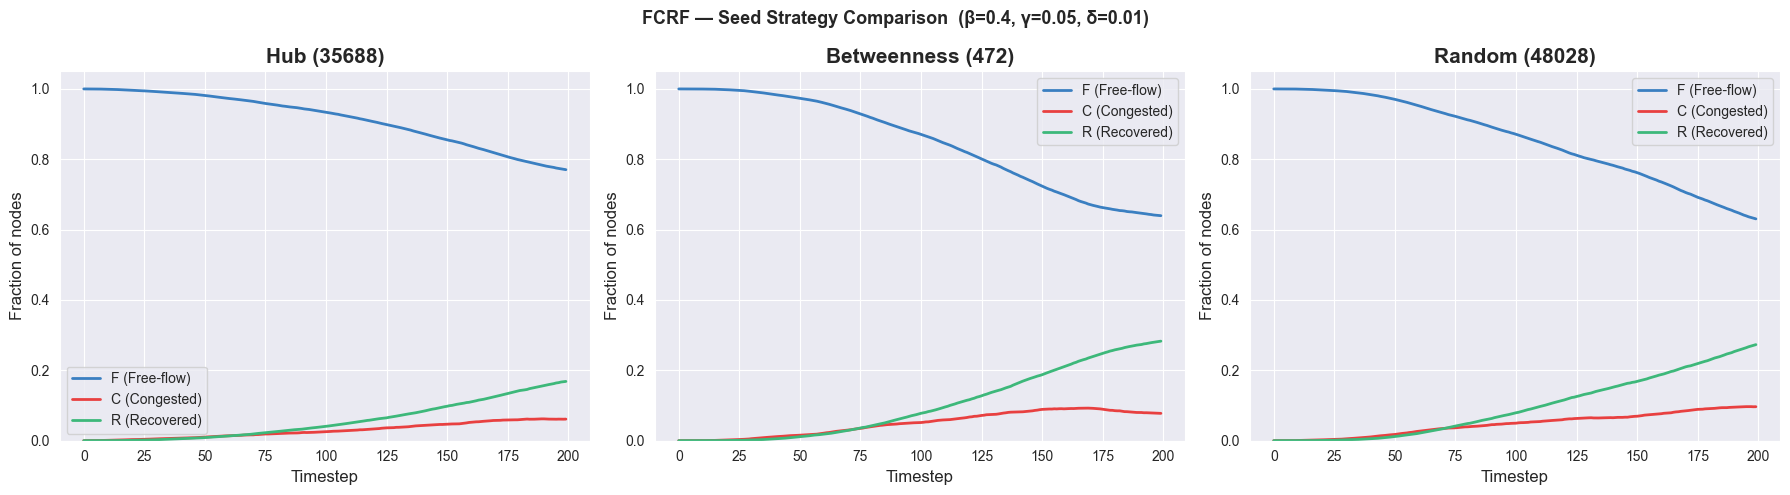

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
results_seed = {}

for ax, (label, seed_list) in zip(axes, seeds.items()):
    history, final_state = fcr_simulation(G, seed_list, BETA, GAMMA, DELTA, rng_seed=42)
    results_seed[label] = history
    plot_fcr(history, title=label, ax=ax)

    peak_C = max(history['C']) / N_rn
    peak_R = history['R'][-1] / N_rn
    print(f'{label}')
    print(f'  Peak Congested : {peak_C*100:.2f}% at step {np.argmax(history['C'])}')
    print(f'  Peak Recovered : {peak_R*100:.2f}% (recovered size)')
    print()

plt.suptitle(f'FCRF — Seed Strategy Comparison  (β={BETA}, γ={GAMMA}, δ={DELTA})', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.2 Parameter Sensitivity Sweep

Different values of congestion spread, recovery, and re-congestion rates are tested to observe their effects on traffic dynamics. Higher spread rates cause faster and larger congestion outbreaks, while higher recovery rates help congestion clear more quickly. Increased re-susceptibility leads to recurring congestion patterns, similar to repeated rush-hour traffic.

In [23]:
top_10_bw = [x[0] for x in top_bw]

In [24]:
BASE = dict(beta=BETA, gamma=GAMMA, delta=DELTA)

R0_base = BASE['beta'] * k_avg / BASE['gamma']
print(f'Mean degree k̄ = {k_avg:.3f}')
print(f'R₀ (baseline) = β·k̄/γ = {BASE["beta"]}·{k_avg:.3f}/{BASE["gamma"]} = {R0_base:.2f}')

SWEEPS = {
    'β — spread rate\n(γ=0.05, δ=0.01 fixed)': {
        'param': 'beta',
        'values': [0.05, 0.15, 0.40, 0.65, 0.85],
    },
    'γ — recovery rate\n(β=0.40, δ=0.01 fixed)': {
        'param': 'gamma',
        'values': [0.01, 0.03, 0.05, 0.15, 0.40],
    },
    'δ — re-susceptibility\n(β=0.40, γ=0.05 fixed)': {
        'param': 'delta',
        'values': [0.00, 0.01, 0.05, 0.15, 0.50],
    }
}

Mean degree k̄ = 2.450
R₀ (baseline) = β·k̄/γ = 0.4·2.450/0.05 = 19.60


In [25]:
sweep_results = {}

for label, cfg in SWEEPS.items():
    sweep_results[label] = []
    param_name = cfg['param']
    print(f'{label.splitlines()[0]}')
    for val in cfg['values']:
        kw = {**BASE, param_name: val}
        R0 = kw['beta'] * k_avg / kw['gamma']
        history, _ = fcr_simulation(
            G, [hub_seed],
            beta=kw['beta'], gamma=kw['gamma'], delta=kw['delta'],
            max_steps=200, rng_seed=42,
        )
        peak_C = max(history['C']) / N_rn
        t_peak = int(np.argmax(history['C']))
        final_C = history['C'][-1] / N_rn
        sweep_results[label].append({
            'value': val, 'history': history,
            'peak_c': peak_C, 't_peak': t_peak,
            'final_C': final_C, 'R0': R0,
        })
        baseline_marker = ' ← baseline' if val == BASE[param_name] else ''
        print(f'  {param_name}={val:.2f}  R₀={R0:5.2f}  '
              f'peak_C={peak_C*100:5.1f}%  t_peak={t_peak:>3d}  '
              f'final_C={final_C*100:5.1f}%{baseline_marker}')

print()

β — spread rate
  beta=0.05  R₀= 2.45  peak_C=  0.0%  t_peak=141  final_C=  0.0%
  beta=0.15  R₀= 7.35  peak_C=  0.2%  t_peak=149  final_C=  0.1%
  beta=0.40  R₀=19.60  peak_C=  6.2%  t_peak=189  final_C=  6.1% ← baseline
  beta=0.65  R₀=31.85  peak_C= 16.1%  t_peak=191  final_C= 15.9%
  beta=0.85  R₀=41.65  peak_C= 19.7%  t_peak=164  final_C= 12.9%
γ — recovery rate
  gamma=0.01  R₀=97.99  peak_C= 23.5%  t_peak=199  final_C= 23.5%
  gamma=0.03  R₀=32.66  peak_C= 10.9%  t_peak=199  final_C= 10.9%
  gamma=0.05  R₀=19.60  peak_C=  6.2%  t_peak=189  final_C=  6.1% ← baseline
  gamma=0.15  R₀= 6.53  peak_C=  0.7%  t_peak=185  final_C=  0.6%
  gamma=0.40  R₀= 2.45  peak_C=  0.0%  t_peak=  5  final_C=  0.0%
δ — re-susceptibility
  delta=0.00  R₀=19.60  peak_C=  5.2%  t_peak=193  final_C=  5.2%
  delta=0.01  R₀=19.60  peak_C=  6.2%  t_peak=189  final_C=  6.1% ← baseline
  delta=0.05  R₀=19.60  peak_C= 14.7%  t_peak=199  final_C= 14.7%
  delta=0.15  R₀=19.60  peak_C= 23.1%  t_peak=199  final_C

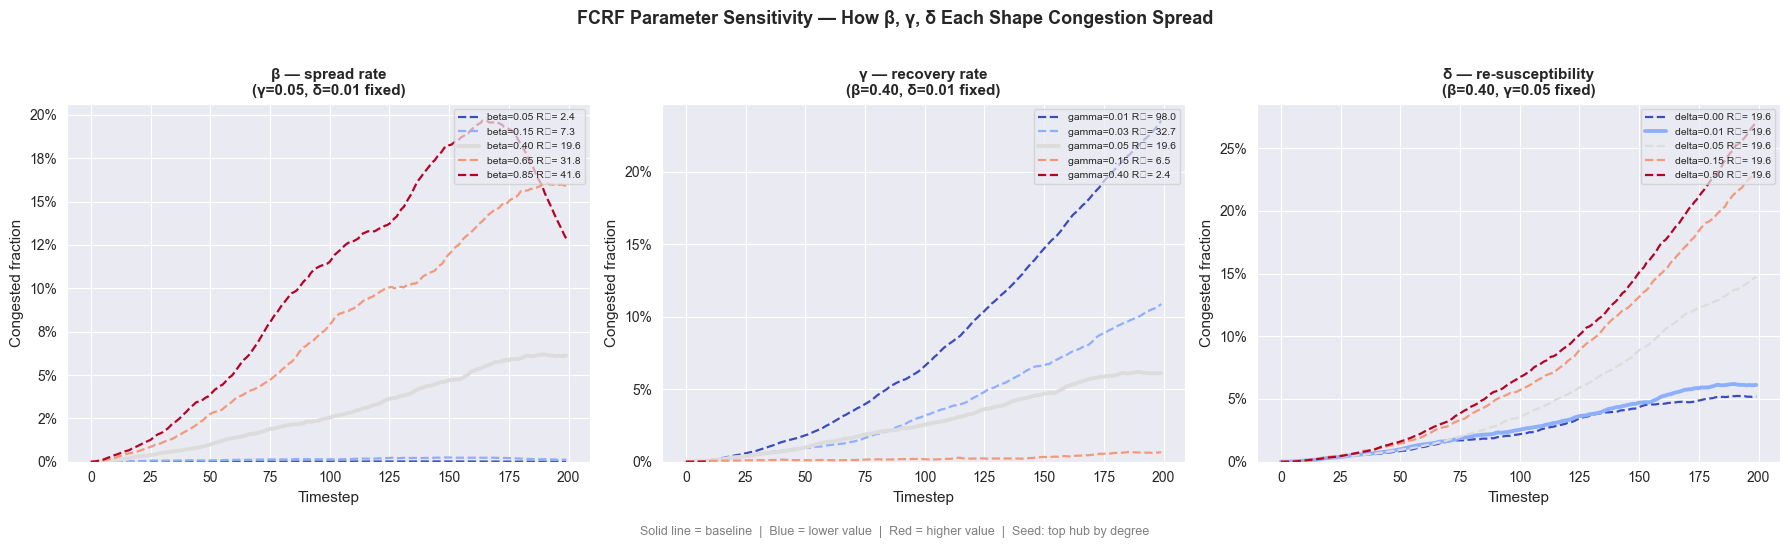

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
palette = plt.cm.coolwarm

for ax, (label, results) in zip(axes, sweep_results.items()):
    n_vals = len(results)
    param = list(SWEEPS[label].values())[0]

    for i, r in enumerate(results):
        color = palette(i / (n_vals - 1))
        C_frac = [v / N_rn for v in r['history']['C']]
        is_base = r['value'] == BASE[SWEEPS[label]['param']]
        lw = 2.8 if is_base else 1.6
        ls = '-' if is_base else '--'
        lbl = f'{SWEEPS[label]['param']}={r['value']:.2f} R₀= {r['R0']:.1f}'
        ax.plot(C_frac, color=color, lw=lw, ls=ls, label=lbl)
    
    ax.set_xlabel('Timestep', fontsize=11)
    ax.set_ylabel('Congested fraction', fontsize=11)
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.legend(fontsize=7.5, loc='upper right', framealpha=0.7)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.0f}%'))

fig.text(
    0.5, -0.03,
    'Solid line = baseline  |  Blue = lower value  |  Red = higher value  |  '
    'Seed: top hub by degree',
    ha='center', fontsize=9, color='gray'
)
plt.suptitle(
    'FCRF Parameter Sensitivity — How β, γ, δ Each Shape Congestion Spread',
    fontsize=13, fontweight='bold', y=1.02,
)

plt.tight_layout()
plt.show()

### 3.3 Spatial Congestion Spreading — Multi-Origin Snapshots

The simulation visualizes congestion spreading from multiple important intersections over time. Early stages show isolated congestion points, peak stages reveal network-wide spreading along arterial corridors, and final stages highlight persistent bottlenecks that recover slowly.

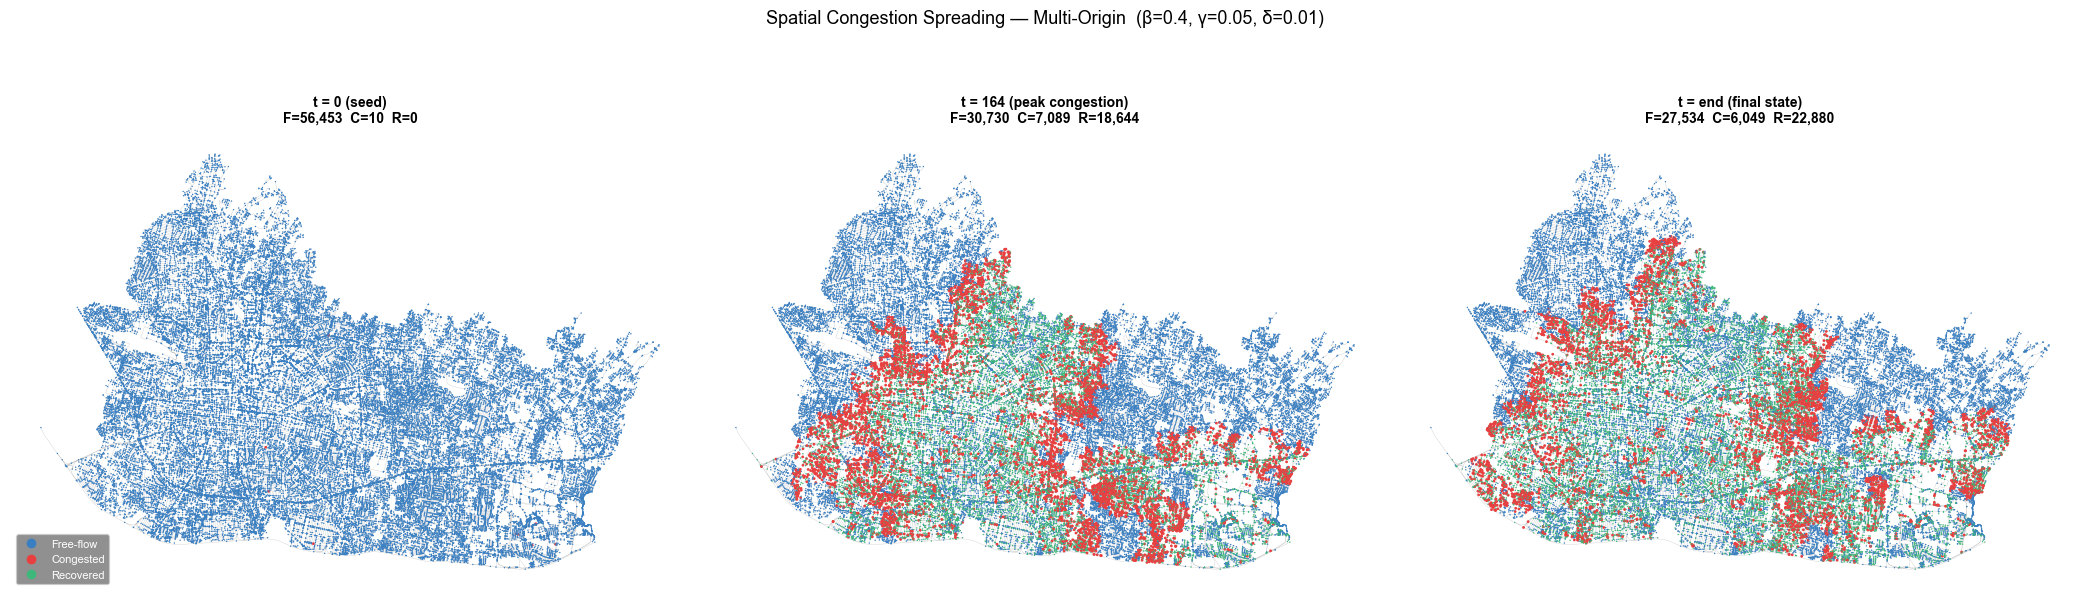

In [27]:
top_10_deg = [x[0] for x in top_degree]

# Run with snapshots
hist_snap, snaps = fcr_simulation(
    G, top_10_deg, BETA, GAMMA, DELTA,
    snapshot_steps=list(range(200)),
    rng_seed=42
)
peak_t = int(np.argmax(hist_snap['C']))

panels = [
    (snaps.get(0, {}), f't = 0 (seed)'),
    (snaps.get(peak_t, {}), f't = {peak_t} (peak congestion)'),
    (snaps['final'], f't = end (final state)'),
]

node_list = list(G.nodes())
xs = np.array([G.nodes[n]['pos'][0] for n in node_list])
ys = np.array([G.nodes[n]['pos'][1] for n in node_list])

fig, axes = plt.subplots(1, 3, figsize=(21, 7), facecolor=BGCOLOR)

for ax, (snap, title) in zip(axes, panels):
    ax.set_facecolor(BGCOLOR)
    if not snap:
        ax.text(0.5, 0.5, 'no snapshot', color='white',
                ha='center', va='center', transform=ax.transAxes)
        ax.set_title(title, color='white')
        continue

    c2g.plot_graph(
        G,
        ax=ax,
        markersize=0,
        edge_color='#1c1c1c',
        edge_linewidth=0.2,
        bgcolor=BGCOLOR,
    )

    colors = [STATE_COLORS.get(snap.get(n, 'F'), '#888888') for n in node_list]
    sizes = [4.0 if snap.get(n, 'F') == 'C' else 1.0 for n in node_list]

    ax.scatter(xs, ys, c=colors, s=sizes,
               zorder=3, linewidths=0)

    f_n = sum(1 for v in snap.values() if v == 'F')
    c_n = sum(1 for v in snap.values() if v == 'C')
    r_n = sum(1 for v in snap.values() if v == 'R')
    ax.set_title(
        f'{title}\nF={f_n:,}  C={c_n:,}  R={r_n:,}',
        color='black', fontsize=10, pad=8
    )

for label, color in STATE_COLORS.items():
    axes[0].plot([], [], 'o', color=color, markersize=6,
                 label={'F': 'Free-flow', 'C': 'Congested', 'R': 'Recovered'}[label])

axes[0].legend(loc='lower left', fontsize=8, framealpha=0.5,
               facecolor='#222', labelcolor='white')
plt.suptitle(
    f'Spatial Congestion Spreading — Multi-Origin  (β={BETA}, γ={GAMMA}, δ={DELTA})',
    color='black', fontsize=13,
)

plt.tight_layout()
plt.show()

## 4. Graph Neural Network (GNN) — Intersection Importance Prediction

We apply a **Graph Convolutional Network (GCN)** to classify every road intersection in the
Lengkong subgraph into one of three importance tiers: **Low**, **Medium**, or **High**.
The model learns from structural graph features and the neighbourhood connectivity pattern,
enabling data-driven identification of critical intersections without requiring traffic sensor data.

In [ ]:
LAT, LON = -6.9275, 107.6235
DIST_M    = 1000

d_lat = DIST_M / 111_000
d_lon = DIST_M / (111_000 * np.cos(np.radians(LAT)))

bbox = (LON - d_lon, LAT - d_lat,   # minx, miny
        LON + d_lon, LAT + d_lat)   # maxx, maxy

In [30]:
print('Downloading Overture Maps data for Lengkong ...')
c2g.load_overture_data(
    place_name='Lengkong, Bandung, Indonesia',
    types=['segment', 'connector'],
    output_dir='./datasets/',
    prefix='lengkong_',
    save_to_file=True,
    return_data=False,
)

{}

In [31]:
segments_gdf = gpd.read_file('./datasets/lengkong_segment.geojson')
connectors_gdf = gpd.read_file('./datasets/lengkong_connector.geojson')

DRIVEABLE = {
    'motorway', 'trunk', 'primary', 'secondary', 'tertiary',
    'residential', 'service', 'living_street', 'unclassified'
}
segments_gdf = segments_gdf[
    (segments_gdf['subtype'] == 'road') &
    (segments_gdf['class'].isin(DRIVEABLE))
].reset_index(drop=True)

In [32]:
local_crs = segments_gdf.estimate_utm_crs()
segments_gdf = segments_gdf.to_crs(local_crs)
connectors_gdf = connectors_gdf.to_crs(local_crs)

In [33]:
processed = c2g.process_overture_segments(
    segments_gdf, connectors_gdf=connectors_gdf,
    get_barriers=True, threshold=1.0,
)
G_raw = c2g.segments_to_graph(processed, as_nx=True)

# Keep only the largest connected component
lcc = max(nx.connected_components(G_raw), key=len)
G_raw = nx.convert_node_labels_to_integers(
    G_raw.subgraph(lcc).copy(), ordering='sorted'
)

Removed 5 invalid geometries


In [ ]:
bbox_wgs84 = shapely_box(*bbox)
bbox_gdf = gpd.GeoDataFrame(geometry=[bbox_wgs84], crs='EPSG:4326')
bbox_proj = bbox_gdf.to_crs(local_crs).geometry.iloc[0]

G = c2g.clip_graph(G_raw, bbox_proj)
print(f'Clipped → Nodes: {G.number_of_nodes():,} | Edges: {G.number_of_edges():,}')

Clipped → Nodes: 1,106 | Edges: 1,409


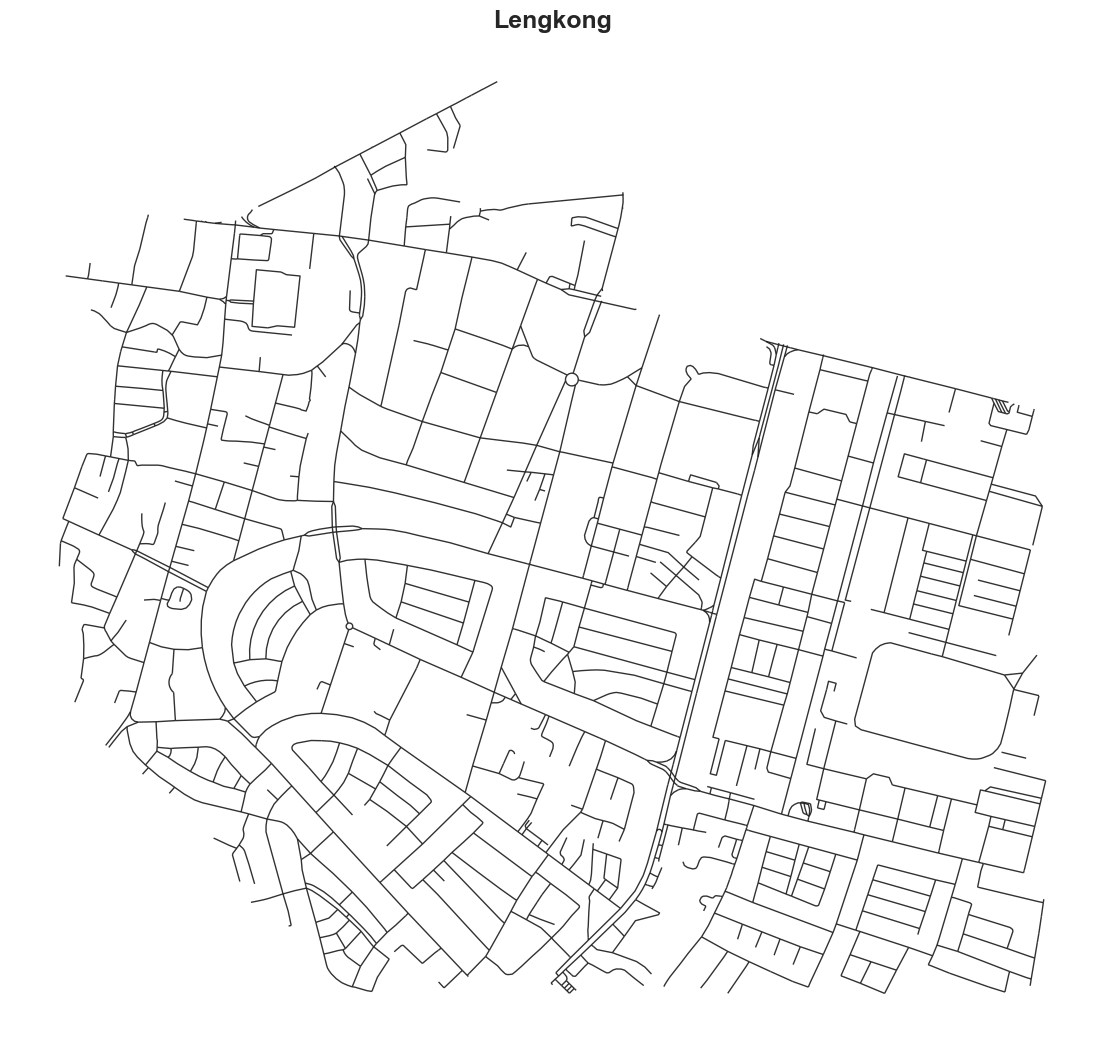

In [37]:
ax = c2g.plot_graph(
    graph=G,
    bgcolor=BGCOLOR,
    figsize=(14, 14),
    markersize=0,
    edge_color='#1c1c1c',
    edge_linewidth=1.0,
    edge_alpha=0.9,
)
ax.set_title('Lengkong', fontsize=18)
plt.show()

In [38]:
G_gcn = nx.Graph(G)

print(type(G_gcn))

<class 'networkx.classes.graph.Graph'>


### 4.1 Feature Engineering

Five structural centrality measures are computed for each node and normalised
to the [0, 1] range using Min-Max scaling:

| Feature | Role |
|---|---|
| **Degree** | How many roads directly connect to this intersection |
| **Betweenness centrality** | Fraction of shortest paths that pass through this node |
| **Closeness centrality** | How quickly this node can reach all others |
| **PageRank** | Weighted importance based on incoming connection quality |
| **Clustering coefficient** | How densely connected the node's immediate neighbours are |

The three features fed into the GCN as `X` are **closeness**, **PageRank**, and **clustering**,
chosen because they capture complementary aspects of a node's structural role —
global reachability, weighted prestige, and local cohesion respectively.

In [39]:
print("Degree...")
degree_dict = dict(G_gcn.degree())

print("Betweenness...")
betweenness = nx.betweenness_centrality(G_gcn)

print("Closeness...")
closeness = nx.closeness_centrality(G_gcn)

print("PageRank...")
pagerank = nx.pagerank(G_gcn)

print("Clustering...")
clustering = nx.clustering(G_gcn)

print("Done!")

Degree...
Betweenness...
Closeness...
PageRank...
Clustering...
Done!


In [41]:
nodes = list(G_gcn.nodes())

degree_values = np.array([
    degree_dict[node]
    for node in nodes
]).reshape(-1,1)

between_values = np.array([
    betweenness[node]
    for node in nodes
]).reshape(-1,1)

close_values = np.array([
    closeness[node]
    for node in nodes
]).reshape(-1,1)

pagerank_values = np.array([
    pagerank[node]
    for node in nodes
]).reshape(-1,1)

cluster_values = np.array([
    clustering[node]
    for node in nodes
]).reshape(-1,1)

scaler = MinMaxScaler()

degree_norm = scaler.fit_transform(
    degree_values
).flatten()

between_norm = scaler.fit_transform(
    between_values
).flatten()

close_norm = scaler.fit_transform(
    close_values
).flatten()

pagerank_norm = scaler.fit_transform(
    pagerank_values
).flatten()

cluster_norm = scaler.fit_transform(
    cluster_values
).flatten()

In [ ]:
X = np.column_stack([
    close_norm,
    pagerank_norm,
    cluster_norm

])

X = torch.tensor(
    X,
    dtype=torch.float
)

print(X.shape)

torch.Size([1106, 3])


4.2 Label Construction — Composite Importance Score

Because real traffic labels are unavailable, an importance score is created using a weighted combination of centrality measures:

importance=0.4×betweenness+0.3×degree+0.2×PageRank+0.1×closeness

Betweenness is given the highest weight because it best represents important traffic routes. The scores are then divided into three classes using the 33rd and 66th percentiles:

- 0 (Low importance): Peripheral intersections
- 1 (Medium importance): Regular intersections
- 2 (High importance): Major intersections and bottlenecks

Using percentile thresholds keeps the class distribution balanced for model training.

In [ ]:
importance_score = (
    0.4 * between_norm +
    0.3 * degree_norm +
    0.2 * pagerank_norm +
    0.1 * close_norm
)

In [ ]:
q1 = np.quantile(
    importance_score,
    0.33
)

q2 = np.quantile(
    importance_score,
    0.66
)

y = []

for score in importance_score:
    if score <= q1:
        label = 0

    elif score <= q2:
        label = 1

    else:
        label = 2
    y.append(label)

y = torch.tensor(
    y,
    dtype=torch.long
)

print(y.shape)

torch.Size([1106])


### 4.3 Graph Data Preparation

All city2graph node and edge attributes are stripped before converting to a PyTorch Geometric
`Data` object, because `from_networkx` cannot handle the geometry and road-class attributes
stored by the pipeline. A clean topology-only graph is rebuilt first, then `data.x` and `data.y`
are attached manually. The dataset is split **80 % training / 20 % test** using a random permutation.

In [46]:
# hapus node attributes
for node in G_gcn.nodes():
    G_gcn.nodes[node].clear()

# hapus edge attributes
for u, v in G_gcn.edges():
    G_gcn.edges[u, v].clear()

# convert to pytorch geometric
G_clean = nx.Graph()
G_clean.add_nodes_from(G_gcn.nodes())
G_clean.add_edges_from(G_gcn.edges())

data = from_networkx(G_clean)
data.x = X
data.y = y

print(data)

Data(edge_index=[2, 2818], num_nodes=1106, x=[1106, 3], y=[1106])


In [47]:
num_nodes = data.num_nodes
indices = np.random.permutation(num_nodes)

train_size = int(0.8 * num_nodes)
train_idx = indices[:train_size]
test_idx = indices[train_size:]

data.train_mask = torch.zeros(
    num_nodes,
    dtype=torch.bool
)

data.test_mask = torch.zeros(
    num_nodes,
    dtype=torch.bool
)

data.train_mask[train_idx] = True
data.test_mask[test_idx] = True
print(data)

Data(edge_index=[2, 2818], num_nodes=1106, x=[1106, 3], y=[1106], train_mask=[1106], test_mask=[1106])


In [48]:
device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'cpu'
)

print(device)
data = data.to(device)

cpu


### 4.4 GCN Architecture

In [49]:
class GCN(torch.nn.Module):

    def __init__(self):
        super().__init__()
        self.conv1 = GCNConv(3, 16)
        self.conv2 = GCNConv(16, 3)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        return x


model = GCN().to(device)

print(model)

GCN(
  (conv1): GCNConv(3, 16)
  (conv2): GCNConv(16, 3)
)


### 4.5 Training

The model is trained for **20 000 epochs** using the **Adam** optimiser (lr = 0.01) and **Cross-Entropy loss** computed only over the training mask.

In [50]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

criterion = torch.nn.CrossEntropyLoss()

model.train()

for epoch in range(20001):
    optimizer.zero_grad()
    out = model(data)
    loss = criterion(
        out[data.train_mask],
        data.y[data.train_mask]
    )

    loss.backward()
    optimizer.step()

    if epoch % 1000 == 0:
        print(
            f"Epoch {epoch} | Loss: {loss.item():.4f}"
        )

Epoch 0 | Loss: 1.0953
Epoch 1000 | Loss: 0.5701
Epoch 2000 | Loss: 0.4897
Epoch 3000 | Loss: 0.4442
Epoch 4000 | Loss: 0.4162
Epoch 5000 | Loss: 0.3987
Epoch 6000 | Loss: 0.3872
Epoch 7000 | Loss: 0.3799
Epoch 8000 | Loss: 0.3752
Epoch 9000 | Loss: 0.3692
Epoch 10000 | Loss: 0.3628
Epoch 11000 | Loss: 0.3603
Epoch 12000 | Loss: 0.3586
Epoch 13000 | Loss: 0.3577
Epoch 14000 | Loss: 0.3566
Epoch 15000 | Loss: 0.3557
Epoch 16000 | Loss: 0.3551
Epoch 17000 | Loss: 0.3547
Epoch 18000 | Loss: 0.3545
Epoch 19000 | Loss: 0.3541
Epoch 20000 | Loss: 0.3535


### 4.6 Evaluation

The trained model is evaluated on the held-out 20%The model is trained for **20 000 epochs** using the **Adam** optimiser (lr = 0.01) and
**Cross-Entropy loss** computed only over the training mask.

In [51]:
model.eval()

pred = model(data).argmax(dim=1)
correct = (
    pred[data.test_mask] == data.y[data.test_mask]
).sum()

acc = int(correct) / int(data.test_mask.sum())
print(f'Accuracy: {acc:.4f}')
print()

print(
    classification_report(
        data.y[data.test_mask].cpu(),
        pred[data.test_mask].cpu()
    )
)

Accuracy: 0.8288

              precision    recall  f1-score   support

           0       0.93      0.96      0.95        81
           1       0.72      0.79      0.76        68
           2       0.83      0.71      0.76        73

    accuracy                           0.83       222
   macro avg       0.82      0.82      0.82       222
weighted avg       0.83      0.83      0.83       222



### 4.7 Spatial Visualization of Predictions

Each intersection in Lengkong is colored by its **predicted importance tier**:

| Colour | Class | Interpretation |
|---|---|---|
| 🟢 Green | Low importance | Quiet residential or dead-end nodes |
| 🟠 Orange | Medium importance | Standard through-traffic junctions |
| 🔴 Red | High importance | Critical arterial bottlenecks |

In [52]:
pred_colors = []

for label in pred.cpu().numpy():

    if label == 0:
        pred_colors.append('green')

    elif label == 1:
        pred_colors.append('orange')

    else:
        pred_colors.append('red')

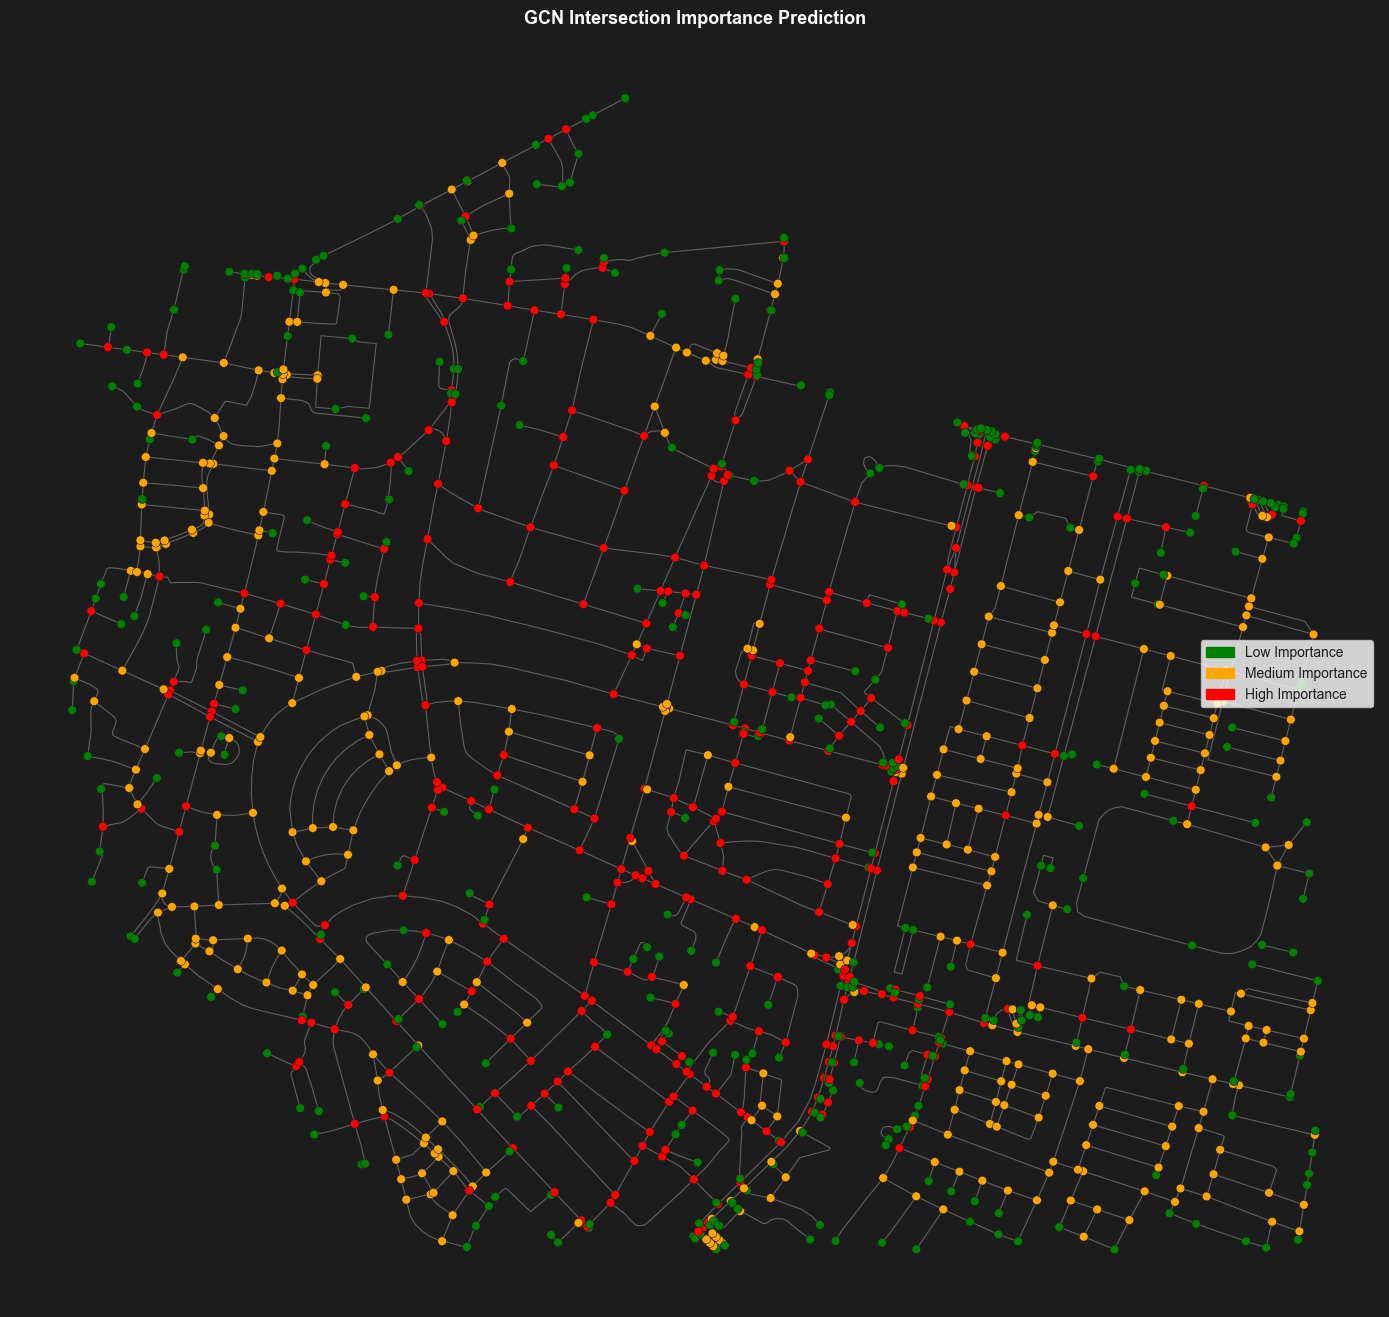

In [54]:
node_list = list(G.nodes())
xs = np.array([G.nodes[n]['pos'][0] for n in node_list])
ys = np.array([G.nodes[n]['pos'][1] for n in node_list])

ax = c2g.plot_graph(
    G,
    bgcolor='#1c1c1c',
    markersize=0, 
    edge_color='#ffffff',
    edge_linewidth=0.8,
    figsize=(14, 14),
)

ax.scatter(
    xs, ys,
    c=pred_colors,
    s=40,
    zorder=3,
    linewidths=0.4,
    edgecolors='#1c1c1c',
)

green_patch  = mpatches.Patch(color='green', label='Low Importance')
orange_patch = mpatches.Patch(color='orange', label='Medium Importance')
red_patch = mpatches.Patch(color='red', label='High Importance')

ax.legend(
    handles=[green_patch, orange_patch, red_patch],
    loc='center right',
    fontsize=10,
    framealpha=0.8,
    facecolor='#ffffff',
    labelcolor='#1c1c1c',
)
ax.set_title(
    'GCN Intersection Importance Prediction', 
    color='#ffffff', 
    fontsize=13,
    fontweight='bold',
    pad=12,
)
plt.tight_layout()
plt.show()

### 📝 Authored by:

- Jason Yehezkiel Wijaya (191900531)  
- Samuel Setyawan (222200206)
- Tiffany Rosaliana Debora Sondakh (191900199)
- Khenny Fileo Suciady (202000235)